[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/08_logistic_regression.ipynb)

# 08 · Logistic Regression: From Lines to Probabilities

**Part 1 — Classical supervised learning** · Notebook 8 of 27

Notebooks 05–07 predicted *numbers*. Now we predict *categories*: spam or not, tumor malignant or benign, which digit is in this image. Logistic regression is the classification counterpart of linear regression, and it's built with exactly the same three-step recipe from CX 4240: **probabilistic model → loss by MLE/MAP → optimizer**. The only change is the first step: instead of Gaussian noise around a line, we use a **coin flip** whose bias depends on the input. Everything else follows. And this model matters far beyond itself: the last layer of almost every neural-network classifier, including the one that picks GPT's next word, is a softmax regression.

**What you'll learn**

1. Why linear regression is the wrong tool for classification
2. The model: Bernoulli likelihood + linear score → the **sigmoid**
3. The loss: **cross-entropy**, derived by MLE
4. The gradient, and why there's no closed-form solution
5. Why the loss is **convex** (ISYE 4600 HW3)
6. Training with gradient descent, from scratch, animated
7. Separable data: why the weights blow up, and how MAP fixes it
8. **Newton's method**: convergence in a handful of steps
9. Nonlinear boundaries with feature maps
10. **Multiclass: softmax regression**, trained on handwritten digits
11. Reading the model: odds ratios and calibrated probabilities

*Course map: CX 4240 Lecture 7 (Logistic Regression) and Lecture 8 (Multi-Class Logistic Regression); ISYE 4600 W8 (Classification: logistic regression and gradient-based training) and HW3 (convexity of logistic regression).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from sklearn.datasets import make_moons, make_circles, load_digits, load_breast_cancer
from sklearn.linear_model import LogisticRegression
print("Ready ✓")

sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def make_two_blobs(n=100, sep=2.0, seed=0):
    r_ = np.random.default_rng(seed)
    X0 = r_.normal([-sep / 2, -sep / 4], 1.0, size=(n, 2))
    X1 = r_.normal([sep / 2, sep / 4], 1.0, size=(n, 2))
    return np.vstack([X0, X1]), np.r_[np.zeros(n), np.ones(n)]

def prob_map(ax, prob_fn, xlim=(-4.5, 4.5), ylim=(-4, 4), n=200, boundary=True):
    """Shade P(y=1|x) over the plane, with the 0.5 contour as the decision boundary."""
    g1, g2 = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    P = prob_fn(np.column_stack([g1.ravel(), g2.ravel()])).reshape(g1.shape)
    ax.contourf(g1, g2, P, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.75, vmin=0, vmax=1)
    if boundary:
        ax.contour(g1, g2, P, levels=[0.5], colors=C["ink"], linewidths=2)
    ax.set(xlim=xlim, ylim=ylim); ax.grid(False)

def scatter_classes(ax, X, y, s=22):
    ax.scatter(*X[y == 0].T, s=s, color=C["blue"], edgecolor="white", linewidth=0.6, label="class 0")
    ax.scatter(*X[y == 1].T, s=s, color=C["red"], edgecolor="white", linewidth=0.6, label="class 1")

Setup complete ✓


Ready ✓


---
## 1. Why linear regression is the wrong tool

Labels are now $y \in \{0, 1\}$. Why not just run linear regression on the 0/1 labels and predict class 1 when the output exceeds 0.5? People do try. Here's what goes wrong, with tumor size as a single feature:

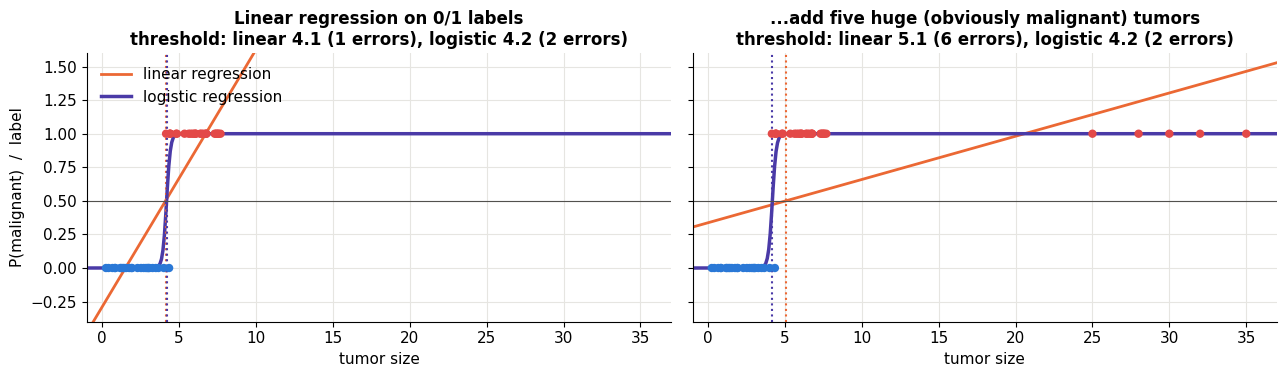

In [2]:
r_ = np.random.default_rng(2)
size_ = np.r_[r_.uniform(0, 4.5, 25), r_.uniform(4, 8, 25)]
lab = np.r_[np.zeros(25), np.ones(25)]
size_out = np.r_[size_, [25, 28, 30, 32, 35]]; lab_out = np.r_[lab, np.ones(5)]      # five very large (obviously malignant) tumors

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True)
for ax, (xs_, ys_, title) in zip(axes, [(size_, lab, "Linear regression on 0/1 labels"), (size_out, lab_out, "...add five huge (obviously malignant) tumors")]):
    A = np.column_stack([np.ones_like(xs_), xs_]); th = np.linalg.lstsq(A, ys_, rcond=None)[0]
    lr = LogisticRegression(C=1e6).fit(xs_[:, None], ys_)
    g = np.linspace(-1, 37, 400)
    ax.scatter(xs_, ys_, s=25, c=[C["red"] if v else C["blue"] for v in ys_], zorder=3)
    ax.plot(g, th[0] + th[1] * g, color=C["orange"], lw=2, label="linear regression")
    ax.plot(g, lr.predict_proba(g[:, None])[:, 1], color=C["violet"], lw=2.5, label="logistic regression")
    cut_lin = (0.5 - th[0]) / th[1]; cut_log = -lr.intercept_[0] / lr.coef_[0, 0]
    ax.axvline(cut_lin, color=C["orange"], ls=":", lw=1.5); ax.axvline(cut_log, color=C["violet"], ls=":", lw=1.5)
    ax.axhline(0.5, color=C["muted"], lw=0.8)
    err_lin = np.sum((xs_ > cut_lin) != ys_); err_log = np.sum((xs_ > cut_log) != ys_)
    ax.set(xlim=(-1, 37), ylim=(-0.4, 1.6), xlabel="tumor size",
           title=f"{title}\nthreshold: linear {cut_lin:.1f} ({err_lin} errors), logistic {cut_log:.1f} ({err_log} errors)")
axes[0].set_ylabel("P(malignant)  /  label"); axes[0].legend(loc="upper left")
fig.tight_layout(); plt.show()

Two problems with the straight line:

1. **Outputs aren't probabilities.** The line goes below 0 and above 1. What does "probability 1.4" mean?
2. **Easy points hurt.** The five huge tumors are obviously malignant, yet least squares *penalizes* the line for predicting far above 1 there, so it flattens the line to reduce that error. That drags the decision threshold from about 4.1 to about 5.1, and the number of mistakes jumps from 1 to 6: medium-sized malignant tumors now get called benign. A good classifier shouldn't be punished for being very sure about obvious cases.

The logistic curve (purple) has neither problem: it stays in $[0, 1]$ and barely notices the extra points, because they're already predicted near 1.

---
## 2. The model: Bernoulli likelihood + linear score

Follow CX 4240's pipeline. **Step 1: the probabilistic model.** A binary label is a coin flip: $y \sim \text{Bernoulli}(p)$, i.e.

$$p(y) = p^{\,y}(1 - p)^{1 - y}, \qquad y \in \{0, 1\}$$

The coin's bias $p$ should depend on the input $x$. The simplest idea is a linear score $\theta^\top x$, but that ranges over all of $\mathbb{R}$, while $p$ must lie in $[0, 1]$. So squash it through the **sigmoid** (logistic) function:

$$p(y = 1 \mid x; \theta) = \sigma(\theta^\top x) = \frac{1}{1 + e^{-\theta^\top x}}$$

Some properties worth knowing:
- $\sigma(0) = 0.5$, $\sigma(z) \to 1$ as $z \to \infty$, $\sigma(z) \to 0$ as $z \to -\infty$.
- **Symmetry:** $1 - \sigma(z) = \sigma(-z)$.
- **Derivative:** $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, which we'll use for the gradient.
- **Inverse = log-odds.** Solving for $z$: $\theta^\top x = \log\dfrac{p}{1 - p}$. The linear score is the **log-odds** ("logit") of class 1. That's what "logistic regression" regresses.

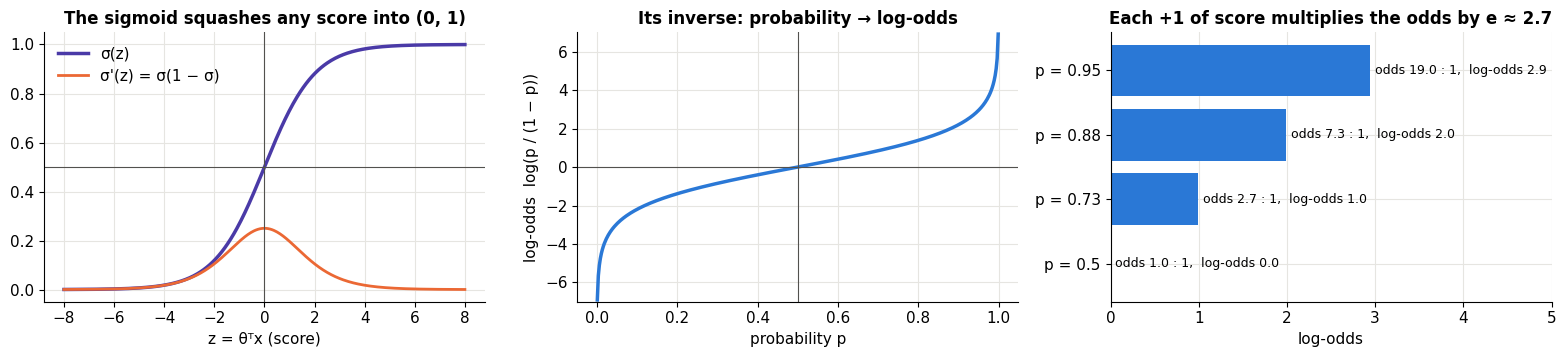

In [3]:
z = np.linspace(-8, 8, 400)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.7))
axes[0].plot(z, sigmoid(z), color=C["violet"], lw=2.5, label="σ(z)")
axes[0].plot(z, sigmoid(z) * (1 - sigmoid(z)), color=C["orange"], lw=2, label="σ'(z) = σ(1 − σ)")
axes[0].axhline(0.5, color=C["muted"], lw=0.8); axes[0].axvline(0, color=C["muted"], lw=0.8)
axes[0].set(xlabel="z = θᵀx (score)", title="The sigmoid squashes any score into (0, 1)"); axes[0].legend()
pp = np.linspace(0.001, 0.999, 400)
axes[1].plot(pp, np.log(pp / (1 - pp)), color=C["blue"], lw=2.5)
axes[1].axhline(0, color=C["muted"], lw=0.8); axes[1].axvline(0.5, color=C["muted"], lw=0.8)
axes[1].set(xlabel="probability p", ylabel="log-odds  log(p / (1 − p))", title="Its inverse: probability → log-odds", ylim=(-7, 7))
for p_ in [0.5, 0.73, 0.88, 0.95]:
    axes[2].barh(f"p = {p_}", np.log(p_ / (1 - p_)), color=C["blue"])
    axes[2].text(np.log(p_ / (1 - p_)) + 0.05, f"p = {p_}", f"odds {p_/(1-p_):.1f} : 1,  log-odds {np.log(p_/(1-p_)):.1f}", va="center", fontsize=9)
axes[2].set(xlim=(0, 5), xlabel="log-odds", title="Each +1 of score multiplies the odds by e ≈ 2.7")
fig.tight_layout(); plt.show()

### The decision boundary is a line (CX 4240 Lecture 7)

We predict class 1 when $p(y = 1\mid x) > 0.5$, i.e. when $\sigma(\theta^\top x) > 0.5$, i.e. when $\theta^\top x > 0$. So the **decision boundary is the set $\theta^\top x = 0$**: a line in 2-D, a plane in 3-D, a hyperplane in general. Logistic regression is a **probabilistic linear classifier**: the boundary is linear, and the distance from it controls the confidence.

With $x = (1, x_1, x_2)$ and $\theta = (b, w_1, w_2)$: the weights $w$ set the boundary's **direction** (they're perpendicular to it) and its **steepness**; the bias $b$ shifts it.

🎚️ **Drive the model by hand.** Rotate the boundary, shift it, and scale the weights up and down. Scaling doesn't move the boundary at all, it only changes how confident the probabilities are.

In [4]:
Xb, yb = make_two_blobs(80, sep=2.5, seed=3)

def plot_logistic_by_hand(angle=30, scale=1.5, bias=0.0):
    w = scale * np.array([np.cos(np.radians(angle)), np.sin(np.radians(angle))])
    prob = lambda P: sigmoid(P @ w + bias)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.2, 1]))
    prob_map(ax1, prob); scatter_classes(ax1, Xb, yb)
    ax1.annotate("", xy=w / np.linalg.norm(w) * 1.5, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=C["ink"], lw=2.5))
    ax1.text(*(w / np.linalg.norm(w) * 1.7), "w", fontsize=13, fontweight="bold")
    p_hat = prob(Xb)
    nll = -np.mean(yb * np.log(p_hat + 1e-12) + (1 - yb) * np.log(1 - p_hat + 1e-12))
    acc = np.mean((p_hat > 0.5) == yb)
    ax1.set(title=f"accuracy {acc:.0%},  cross-entropy loss {nll:.3f}", aspect="equal"); ax1.legend(loc="lower right", fontsize=9)
    s = Xb @ w + bias
    ax2.plot(np.linspace(-12, 12, 300), sigmoid(np.linspace(-12, 12, 300)), color=C["violet"], lw=2)
    ax2.scatter(s, yb + np.random.default_rng(0).uniform(-0.04, 0.04, len(yb)), s=14, c=[C["red"] if v else C["blue"] for v in yb], alpha=0.7)
    ax2.set(xlim=(-12, 12), xlabel="score θᵀx", ylabel="label (jittered)", title="Each point's score on the sigmoid")
    fig.tight_layout(); plt.show()

interact(plot_logistic_by_hand, angle=IntSlider(value=30, min=-180, max=180, step=5, description="w direction°"),
         scale=FloatSlider(value=1.5, min=0.1, max=8, step=0.1, description="‖w‖"),
         bias=FloatSlider(value=0.0, min=-4, max=4, step=0.1, description="bias b"));

---
## 3. The loss: cross-entropy, derived by MLE

**Step 2: derive the loss.** With independent examples, the likelihood is a product of Bernoulli probabilities. Writing $p^i = \sigma(\theta^\top x^i)$:

$$L(\theta) = \prod_{i=1}^m (p^i)^{y^i}(1 - p^i)^{1 - y^i}$$

$$\log L(\theta) = \sum_{i=1}^m \Big[y^i \log p^i + (1 - y^i)\log(1 - p^i)\Big]$$

Maximizing this is the same as minimizing its negative average, the **binary cross-entropy** (or **log loss**):

$$J(\theta) = -\frac1m\sum_{i=1}^m \Big[y^i \log \sigma(\theta^\top x^i) + (1 - y^i)\log\big(1 - \sigma(\theta^\top x^i)\big)\Big]$$

Each term is just $-\log(\text{probability the model gave to the correct answer})$. Confidently right costs ≈ 0; confidently wrong costs a lot (and $-\log 0 = \infty$). CX 4240 writes the same thing compactly by plugging in the sigmoid: $\log L(\theta) = \sum_i \big[(y^i - 1)\theta^\top x^i - \log(1 + e^{-\theta^\top x^i})\big]$. (Notebook 02, section 12, showed this is the cross-entropy between the true labels and the predicted distribution.)

It helps to write the loss in terms of the **margin**. Relabel $\tilde y = 2y - 1 \in \{-1, +1\}$, so a correct prediction means $\tilde y\,\theta^\top x > 0$. Then the per-example loss is

$$\ell = \log\big(1 + e^{-\tilde y\,\theta^\top x}\big)$$

Compare it with other losses you could use for classification:

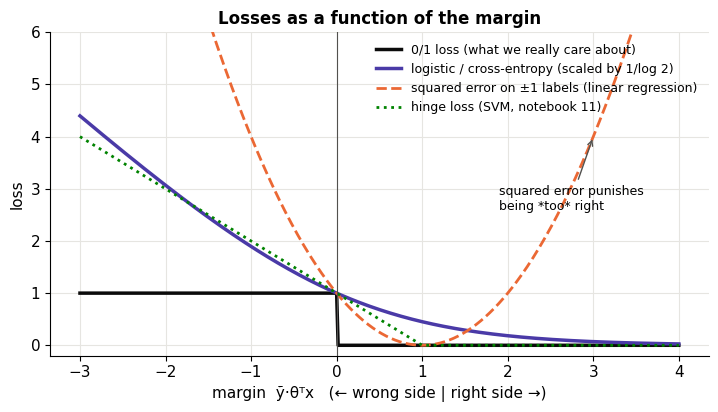

In [5]:
mg = np.linspace(-3, 4, 400)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(mg, (mg <= 0).astype(float), color=C["ink"], lw=2.5, label="0/1 loss (what we really care about)")
ax.plot(mg, np.log1p(np.exp(-mg)) / np.log(2), color=C["violet"], lw=2.5, label="logistic / cross-entropy (scaled by 1/log 2)")
ax.plot(mg, (1 - mg) ** 2, color=C["orange"], lw=2, ls="--", label="squared error on ±1 labels (linear regression)")
ax.plot(mg, np.maximum(0, 1 - mg), color=C["green"], lw=2, ls=":", label="hinge loss (SVM, notebook 11)")
ax.axvline(0, color=C["muted"], lw=0.8)
ax.annotate("squared error punishes\nbeing *too* right", (3, 4), xytext=(1.9, 2.6), fontsize=9, arrowprops=dict(arrowstyle="->", color=C["muted"]))
ax.set(xlabel="margin  ỹ·θᵀx   (← wrong side | right side →)", ylabel="loss", ylim=(-0.2, 6), title="Losses as a function of the margin")
ax.legend(fontsize=9, loc="upper right"); plt.show()

- The **0/1 loss** counts mistakes, which is what we care about, but it's flat almost everywhere (zero gradient) and discontinuous: impossible to optimize with gradients. All the others are smooth-ish **surrogates** that upper-bound it.
- **Squared error** turns back up for large positive margins. That's exactly section 1's problem in a picture: it penalizes being very right.
- **Logistic loss** decreases forever: more confidence on correct examples is always (slightly) better. It's also the only one with a probabilistic interpretation.
- **Hinge loss** is zero once the margin exceeds 1: correct-and-confident examples are ignored entirely. That's the SVM's choice, and why only a few "support vectors" matter there.

> 🤔 **Question: Why not keep the sigmoid model but train it with squared error, $(y - \sigma(\theta^\top x))^2$?**
>
> You can, but the loss is then **non-convex** in $\theta$, with flat regions where the sigmoid saturates (a confidently wrong prediction has almost zero gradient, so learning stalls exactly when it's most needed). The log in cross-entropy cancels the exponential in the sigmoid, which gives a convex loss and gradients that stay large when the model is badly wrong. Let's see both on a 1-D problem:

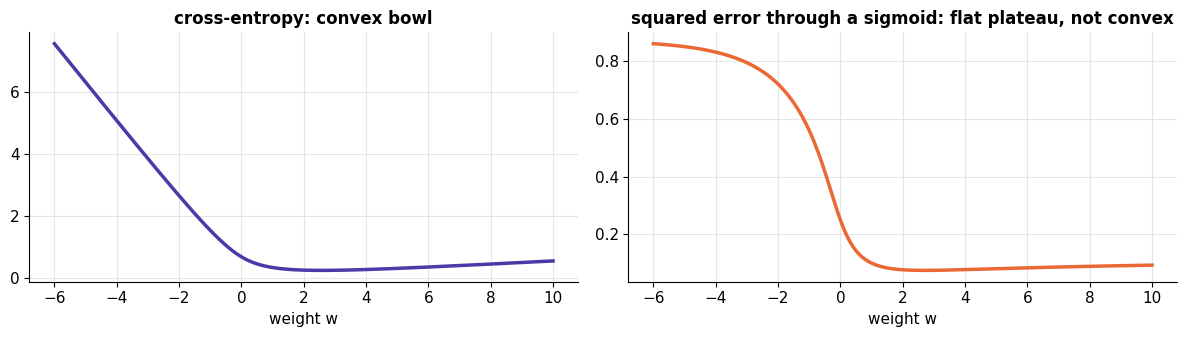

In [6]:
xs1 = np.r_[r_.normal(-1, 1, 30), r_.normal(1.5, 1, 30)]; ys1 = np.r_[np.zeros(30), np.ones(30)]
ws = np.linspace(-6, 10, 400)
ce = [-np.mean(ys1 * np.log(sigmoid(w * xs1) + 1e-12) + (1 - ys1) * np.log(1 - sigmoid(w * xs1) + 1e-12)) for w in ws]
se = [np.mean((ys1 - sigmoid(w * xs1)) ** 2) for w in ws]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.plot(ws, ce, color=C["violet"], lw=2.5); ax1.set(xlabel="weight w", title="cross-entropy: convex bowl")
ax2.plot(ws, se, color=C["orange"], lw=2.5); ax2.set(xlabel="weight w", title="squared error through a sigmoid: flat plateau, not convex")
fig.tight_layout(); plt.show()

---
## 4. The gradient, and why there's no closed form

**Step 3: pick an optimizer.** Differentiate the cross-entropy. Using $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, the terms collapse beautifully (try it on paper: it's three lines):

$$\nabla_\theta J = -\frac1m\sum_{i=1}^m \big(y^i - \sigma(\theta^\top x^i)\big)\,x^i = \frac1m X^\top\big(\sigma(X\theta) - y\big)$$

Compare with linear regression's gradient from notebook 05, $-\frac2m\sum_i (y^i - \theta^\top x^i)\,x^i$: **the same form**, "error times input," with the prediction $\theta^\top x$ replaced by $\sigma(\theta^\top x)$. This "(prediction − target) × input" pattern shows up for every model whose likelihood is in the exponential family (Gaussian, Bernoulli, categorical, Poisson...).

Can we set the gradient to zero and solve, as we did for linear regression? CX 4240 Lecture 7 says no: $\sum_i (y^i - \sigma(\theta^\top x^i))\,x^i = 0$ is a **nonlinear** system in $\theta$ (the $\theta$ is trapped inside the sigmoid). There's no formula. We must iterate.

In [7]:
def bce(theta, X, y, lam=0.0):
    p_ = sigmoid(X @ theta)
    return -np.mean(y * np.log(p_ + 1e-12) + (1 - y) * np.log(1 - p_ + 1e-12)) + lam * np.sum(theta[1:] ** 2)

def bce_grad(theta, X, y, lam=0.0):
    g = X.T @ (sigmoid(X @ theta) - y) / len(y)
    g[1:] += 2 * lam * theta[1:]                       # don't regularize the bias (column 0)
    return g

# Check the analytic gradient against finite differences (notebook 04's habit)
Xb1 = np.column_stack([np.ones(len(Xb)), Xb]); th_test = np.array([0.3, -0.7, 1.1])
num = np.array([(bce(th_test + e, Xb1, yb) - bce(th_test - e, Xb1, yb)) / 2e-6 for e in 1e-6 * np.eye(3)])
print("analytic:", bce_grad(th_test, Xb1, yb).round(6))
print("numeric: ", num.round(6))

analytic: [ 0.064088 -0.785719 -0.187043]
numeric:  [ 0.064088 -0.785719 -0.187043]


---
## 5. Why the loss is convex (ISYE 4600 HW3)

Gradient descent finds the *global* minimum if the loss is convex. Differentiate the gradient once more to get the **Hessian**:

$$\nabla^2 J = \frac1m\sum_{i=1}^m \sigma(\theta^\top x^i)\big(1 - \sigma(\theta^\top x^i)\big)\,x^i x^{i\top} = \frac1m X^\top S X, \qquad S = \text{diag}\big(p^i(1 - p^i)\big)$$

Each weight $p^i(1-p^i)$ is between 0 and ¼, so for any vector $v$:

$$v^\top \nabla^2 J\, v = \frac1m\sum_i p^i(1-p^i)\,(v^\top x^i)^2 \;\ge\; 0$$

The Hessian is positive semi-definite everywhere (notebook 01), so $J$ is **convex**: no bad local minima, and any point where the gradient vanishes is a global minimum. (Strictly convex when $X$ has full column rank and no $p^i$ is exactly 0 or 1.)

In [8]:
# Numerical sanity check: the Hessian's eigenvalues are ≥ 0 at random θ's
for _ in range(3):
    th_r = np.random.default_rng(_).normal(0, 3, 3)
    p_ = sigmoid(Xb1 @ th_r)
    Hs = Xb1.T @ (Xb1 * (p_ * (1 - p_))[:, None]) / len(yb)
    print(f"θ = {th_r.round(2)}  →  Hessian eigenvalues {np.linalg.eigvalsh(Hs).round(4)}")

θ = [ 0.38 -0.4   1.92]  →  Hessian eigenvalues [0.0568 0.1495 0.4624]
θ = [1.04 2.46 0.99]  →  Hessian eigenvalues [0.0225 0.0803 0.0867]
θ = [ 0.57 -1.57 -1.24]  →  Hessian eigenvalues [0.0507 0.0935 0.1041]


---
## 6. Training with gradient descent, from scratch

The update rule (CX 4240 Lecture 7) is the LMS rule with a sigmoid:

$$\theta \leftarrow \theta - \eta\,\frac1m\sum_{i=1}^m \big(\sigma(\theta^\top x^i) - y^i\big)\,x^i$$

Watch the probability map and the decision boundary settle into place:

In [9]:
def train_gd(X, y, lr=0.5, steps=200, lam=0.0, theta0=None):
    th = np.zeros(X.shape[1]) if theta0 is None else theta0.copy()
    hist = [th.copy()]
    for _ in range(steps):
        th -= lr * bce_grad(th, X, y, lam)
        hist.append(th.copy())
    return np.array(hist)

hist = train_gd(Xb1, yb, lr=0.5, steps=150, theta0=np.array([2.0, 1.5, -2.0]))     # a deliberately bad start
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), dpi=72, gridspec_kw=dict(width_ratios=[1.2, 1]))
g1, g2 = np.meshgrid(np.linspace(-4.5, 4.5, 120), np.linspace(-4, 4, 120)); G = np.column_stack([np.ones(g1.size), g1.ravel(), g2.ravel()])
losses = [bce(t, Xb1, yb) for t in hist]
ax2.plot(losses, color=C["light"]); dot, = ax2.plot([], [], "o", color=C["violet"]); ax2.set(xlabel="step", ylabel="cross-entropy", title="loss")

def frame(k):
    ax1.clear()
    P = sigmoid(G @ hist[k]).reshape(g1.shape)
    ax1.contourf(g1, g2, P, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.75)
    ax1.contour(g1, g2, P, levels=[0.5], colors=C["ink"], linewidths=2)
    scatter_classes(ax1, Xb, yb, s=16)
    acc = np.mean((sigmoid(Xb1 @ hist[k]) > 0.5) == yb)
    ax1.set(xlim=(-4.5, 4.5), ylim=(-4, 4), title=f"step {k}: accuracy {acc:.0%}"); ax1.grid(False)
    dot.set_data([k], [losses[k]])
    return []

fig.tight_layout()
show_anim(animation.FuncAnimation(fig, frame, frames=[0, 1, 2, 3, 4, 6, 8, 10, 13, 16, 20, 25, 30, 40, 50, 65, 80, 100, 125, 150], interval=300))

In [10]:
sk = LogisticRegression(C=1e8, max_iter=10000).fit(Xb, yb)          # C = 1/λ: huge C ≈ no regularization
th_long = train_gd(Xb1, yb, lr=1.0, steps=20000)[-1]
print("ours (20k GD steps):", th_long.round(4))
print("scikit-learn:       ", np.r_[sk.intercept_, sk.coef_[0]].round(4))

ours (20k GD steps): [-0.2227  2.5002  1.6943]
scikit-learn:        [-0.2228  2.4999  1.694 ]


---
## 7. Separable data: why the weights blow up

Something strange happens when the two classes can be **perfectly separated** by a line. Any separating line can be made more confident by scaling up $\theta$: every correct point's margin grows, its probability approaches 1, and its loss approaches 0. The loss keeps decreasing **forever**, so there is no minimizer: the MLE **doesn't exist**, and gradient descent sends $\|\theta\|$ to infinity, with probabilities that become absurdly overconfident.

The cure is the same as in notebook 05: a **prior**. With a Gaussian prior $p(\theta) \propto \exp(-\lambda\|\theta\|^2)$, the MAP objective adds $\lambda\|\theta\|^2$ (CX 4240 Lecture 7: the gradient gains $-2\lambda\theta$), which makes the loss strictly convex with a finite minimizer.

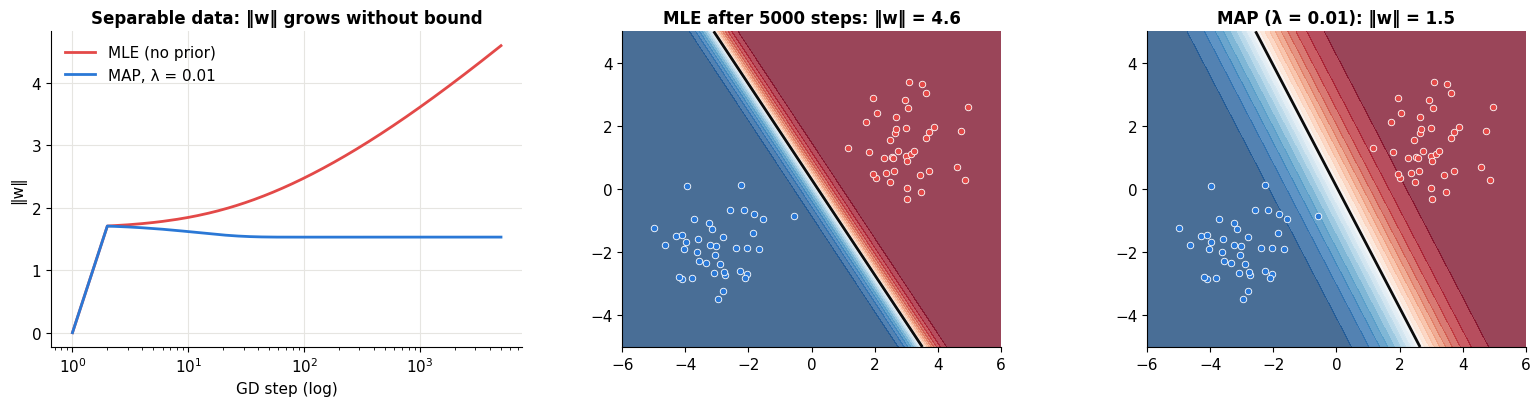

In [11]:
Xsep, ysep = make_two_blobs(40, sep=6.0, seed=5)
Xsep1 = np.column_stack([np.ones(len(Xsep)), Xsep])
h_mle = train_gd(Xsep1, ysep, lr=1.0, steps=5000)
h_map = train_gd(Xsep1, ysep, lr=1.0, steps=5000, lam=0.01)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].semilogx(np.arange(1, 5002), np.linalg.norm(h_mle[:, 1:], axis=1), color=C["red"], lw=2, label="MLE (no prior)")
axes[0].semilogx(np.arange(1, 5002), np.linalg.norm(h_map[:, 1:], axis=1), color=C["blue"], lw=2, label="MAP, λ = 0.01")
axes[0].set(xlabel="GD step (log)", ylabel="‖w‖", title="Separable data: ‖w‖ grows without bound"); axes[0].legend()
for ax, th, name in [(axes[1], h_mle[-1], "MLE after 5000 steps"), (axes[2], h_map[-1], "MAP (λ = 0.01)")]:
    prob_map(ax, lambda P, th=th: sigmoid(th[0] + P @ th[1:]), xlim=(-6, 6), ylim=(-5, 5)); scatter_classes(ax, Xsep, ysep)
    ax.set(title=f"{name}: ‖w‖ = {np.linalg.norm(th[1:]):.1f}", aspect="equal")
fig.tight_layout(); plt.show()

The unregularized weights grow slowly (roughly logarithmically in the number of steps) but **never stop**: run it longer and the band of uncertainty around the boundary keeps narrowing toward a hard cliff, with near-100% confidence just a hair away from the line, purely because these 80 training points happened to be separable. The regularized one settles at a finite $\|w\|$ and keeps sensible, graded probabilities. This matters a lot in high dimensions: with more features than examples, data is almost always separable, so **some regularization is essentially mandatory**. (That's why scikit-learn's `LogisticRegression` regularizes by default, with $C = 1/\lambda = 1$.)

> 🤔 **Question: Then why does the unregularized boundary still look reasonable?**
>
> Because gradient descent has an **implicit bias**: on separable data, the *direction* of $\theta$ converges to the maximum-margin separator, the same boundary an SVM would find (Soudry et al., 2018). The norm diverges but the direction settles. It's another case of "the training procedure regularizes for you," like double descent in notebook 06.

---
## 8. Newton's method: convergence in a handful of steps

Logistic regression has few parameters and a cheap Hessian, so we can use **second-order** information. Newton's method replaces the fixed step with the step that would jump straight to the minimum of the local quadratic approximation (notebook 03's ravine problem disappears, because the Hessian rescales every direction):

$$\theta \leftarrow \theta - \big(\nabla^2 J\big)^{-1}\nabla J = \theta - (X^\top S X)^{-1}X^\top(\sigma(X\theta) - y)$$

Rearranged, each step is a weighted least-squares problem, so this algorithm is also called **iteratively reweighted least squares (IRLS)**. It's what classic statistics packages (R's `glm`) use.

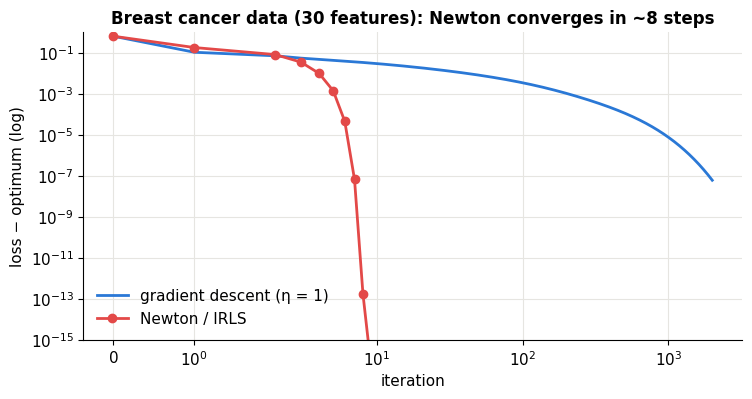

In [12]:
Xbc, ybc = load_breast_cancer(return_X_y=True)
Xbc = (Xbc - Xbc.mean(0)) / Xbc.std(0); Xbc1 = np.column_stack([np.ones(len(ybc)), Xbc])
lam_bc = 1e-3

def newton(X, y, lam, steps=10):
    th = np.zeros(X.shape[1]); hist = [th.copy()]
    R = 2 * lam * np.eye(X.shape[1]); R[0, 0] = 0
    for _ in range(steps):
        p_ = sigmoid(X @ th)
        H = X.T @ (X * (p_ * (1 - p_))[:, None]) / len(y) + R
        th = th - np.linalg.solve(H, bce_grad(th, X, y, lam))
        hist.append(th.copy())
    return np.array(hist)

h_newton = newton(Xbc1, ybc, lam_bc, steps=10)
h_gd = train_gd(Xbc1, ybc, lr=1.0, steps=2000, lam=lam_bc)
best = bce(h_newton[-1], Xbc1, ybc, lam_bc)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.semilogy([bce(t, Xbc1, ybc, lam_bc) - best + 1e-16 for t in h_gd], color=C["blue"], lw=2, label="gradient descent (η = 1)")
ax.semilogy([bce(t, Xbc1, ybc, lam_bc) - best + 1e-16 for t in h_newton], "-o", color=C["red"], lw=2, label="Newton / IRLS")
ax.set(xscale="symlog", xlabel="iteration", ylabel="loss − optimum (log)", ylim=(1e-15, 1),
       title="Breast cancer data (30 features): Newton converges in ~8 steps"); ax.legend()
plt.show()

Newton's error **squares** at every step near the optimum (quadratic convergence: 1e-2, 1e-4, 1e-8, 1e-16), while gradient descent creeps along linearly. The price is forming and solving with a $d \times d$ Hessian: $O(d^3)$ per step. For 30 features that's nothing; for a neural network with a billion parameters it's impossible, which is why deep learning sticks to first-order methods like Adam.

---
## 9. Nonlinear boundaries with feature maps

Logistic regression's boundary is linear in the features. Just like polynomial regression in notebook 05, we can get curved boundaries by feeding it **transformed features**: $x_1, x_2 \to x_1, x_2, x_1^2, x_1x_2, x_2^2, \dots$ The boundary $\theta^\top\phi(x) = 0$ is linear in $\phi$-space but curved in the original space.

🎚️ **Choose a dataset, a polynomial degree and a regularization strength:**

In [13]:
def poly_features(X, degree):
    cols = [np.ones(len(X))]
    for d in range(1, degree + 1):
        for i in range(d + 1):
            cols.append(X[:, 0] ** (d - i) * X[:, 1] ** i)
    return np.column_stack(cols)

datasets = {"moons": make_moons(200, noise=0.25, random_state=0), "circles": make_circles(200, noise=0.12, factor=0.5, random_state=0),
            "blobs (linear)": make_two_blobs(100, sep=2.5, seed=1)}

def plot_poly_logistic(dataset="moons", degree=3, log10_lam=-4.0):
    X_, y_ = datasets[dataset]
    mu_, sd_ = X_.mean(0), X_.std(0); Z_ = (X_ - mu_) / sd_
    Phi = poly_features(Z_, degree); s_ = Phi[:, 1:].std(0); Phi[:, 1:] /= s_
    th = newton(Phi, y_, 10 ** log10_lam, steps=25)[-1]
    def prob(P):
        F = poly_features((P - mu_) / sd_, degree); F[:, 1:] /= s_
        return sigmoid(F @ th)
    pad = 0.6
    fig, ax = plt.subplots(figsize=(6.5, 5))
    prob_map(ax, prob, xlim=(X_[:, 0].min() - pad, X_[:, 0].max() + pad), ylim=(X_[:, 1].min() - pad, X_[:, 1].max() + pad))
    scatter_classes(ax, X_, y_, s=18)
    ax.set(title=f"degree {degree} ({Phi.shape[1]} features), λ = 1e{log10_lam:.1f}\ntraining accuracy {np.mean((sigmoid(Phi @ th) > 0.5) == y_):.0%}")
    plt.show()

interact(plot_poly_logistic, dataset=widgets.Dropdown(options=list(datasets), value="moons", description="data"),
         degree=IntSlider(value=3, min=1, max=10, description="degree"),
         log10_lam=FloatSlider(value=-4, min=-8, max=0, step=0.5, description="log₁₀ λ"));

High degree with tiny $\lambda$ gives a wiggly boundary that wraps around individual points: overfitting, exactly as in notebooks 05–06. As with regression, the catch is that **you** have to pick the features. Neural networks (notebook 19) learn the feature map instead; a neural-network classifier is literally logistic regression on top of learned features.

---
## 10. Multiclass: softmax regression

With $K$ classes, the label is a draw from a **categorical** distribution (a $K$-sided die). Give each class its own weight vector $\theta_k$ and score $z_k = \theta_k^\top x$, then turn the $K$ scores into probabilities with the **softmax** (CX 4240 Lecture 8):

$$p(y = k \mid x) = \frac{e^{\theta_k^\top x}}{\sum_{j=1}^K e^{\theta_j^\top x}}$$

Exponentiate (making everything positive), then normalize (making it sum to 1). For $K = 2$ this reduces exactly to the sigmoid of the score difference. Encode the label as a **one-hot** vector $y^i \in \{0,1\}^K$; the MLE loss is the **categorical cross-entropy**, and its gradient has the familiar form:

$$J = -\frac1m\sum_i\sum_k y^i_k \log p^i_k, \qquad \nabla_{\theta_k} J = \frac1m\sum_i \big(p^i_k - y^i_k\big)\,x^i$$

Prediction minus target, times input, once more. The decision regions are separated by lines where two classes' scores tie, so softmax regression is still a linear classifier (CX 4240 Lecture 8).

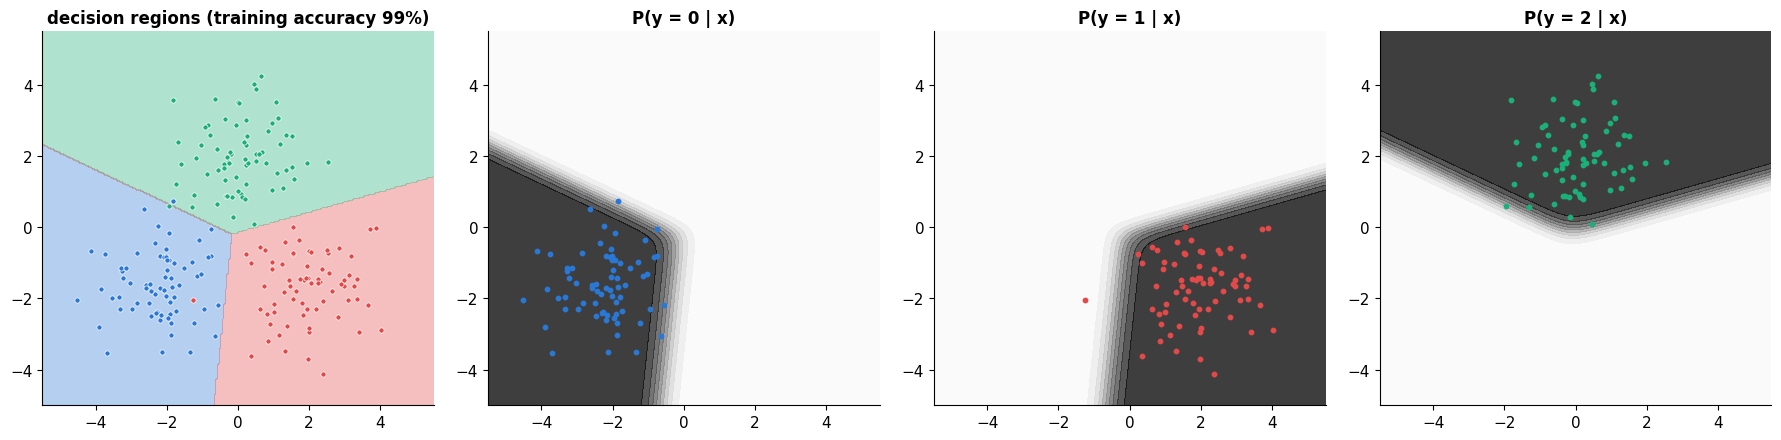

In [14]:
def softmax(Z):
    Z = Z - Z.max(1, keepdims=True)              # subtracting the max doesn't change the result but avoids overflow
    E = np.exp(Z)
    return E / E.sum(1, keepdims=True)

def train_softmax(X, y, K, lr=0.5, steps=500, lam=1e-4, record_every=0):
    m_, d_ = X.shape; Y = np.eye(K)[y]; Theta = np.zeros((d_, K)); hist = []
    for t in range(steps):
        P = softmax(X @ Theta)
        G = X.T @ (P - Y) / m_ + 2 * lam * np.r_[np.zeros((1, K)), Theta[1:]]
        Theta -= lr * G
        if record_every and t % record_every == 0: hist.append(Theta.copy())
    return Theta, hist

r_ = np.random.default_rng(7)
centers = np.array([[-2, -1.5], [2, -1.5], [0, 2]])
X3 = np.vstack([r_.normal(c, 1.0, size=(70, 2)) for c in centers]); y3 = np.repeat([0, 1, 2], 70)
X31 = np.column_stack([np.ones(len(X3)), X3])
Theta3, _ = train_softmax(X31, y3, 3, steps=2000)

g1, g2 = np.meshgrid(np.linspace(-5.5, 5.5, 250), np.linspace(-5, 5.5, 250))
Pg = softmax(np.column_stack([np.ones(g1.size), g1.ravel(), g2.ravel()]) @ Theta3)
cls_cols = [C["blue"], C["red"], C["aqua"]]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
from matplotlib.colors import ListedColormap
axes[0].contourf(g1, g2, Pg.argmax(1).reshape(g1.shape), levels=[-0.5, 0.5, 1.5, 2.5], colors=cls_cols, alpha=0.35)
for k in range(3):
    axes[0].scatter(*X3[y3 == k].T, s=14, color=cls_cols[k], edgecolor="white", linewidth=0.5)
    axes[k + 1].contourf(g1, g2, Pg[:, k].reshape(g1.shape), levels=np.linspace(0, 1, 11), cmap="Greys", alpha=0.8)
    axes[k + 1].scatter(*X3[y3 == k].T, s=10, color=cls_cols[k])
    axes[k + 1].set(title=f"P(y = {k} | x)")
axes[0].set(title=f"decision regions (training accuracy {np.mean(softmax(X31 @ Theta3).argmax(1) == y3):.0%})")
for ax in axes: ax.set(aspect="equal"); ax.grid(False)
fig.tight_layout(); plt.show()

### Softmax regression on handwritten digits

scikit-learn bundles 1,797 handwritten digits as 8×8 grayscale images: 64 pixel features, 10 classes. Softmax regression treats each image as a vector of 64 numbers and learns one 64-weight template per digit.

train accuracy 97.3%,  test accuracy 97.4%


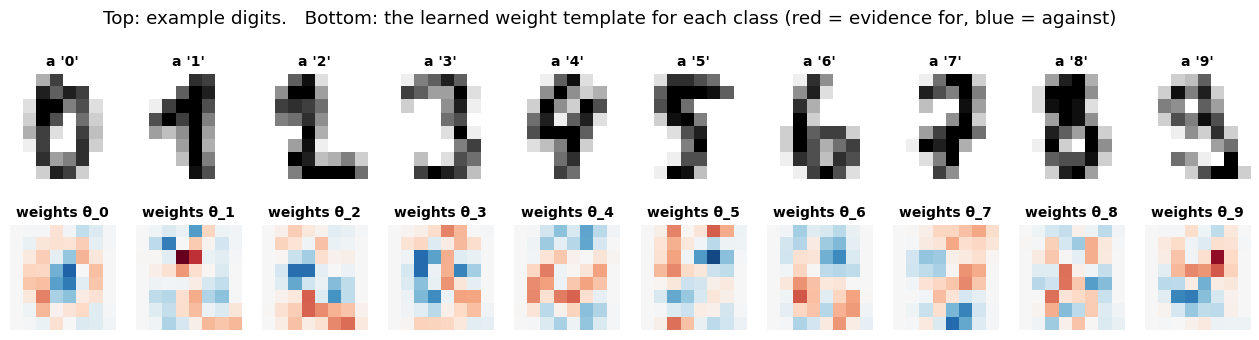

In [15]:
digits = load_digits()
Xg, yg = digits.data / 16.0, digits.target
perm = np.random.default_rng(0).permutation(len(yg)); tr_i, te_i = perm[:1300], perm[1300:]
Xg1 = np.column_stack([np.ones(len(yg)), Xg])
ThetaD, histD = train_softmax(Xg1[tr_i], yg[tr_i], 10, lr=0.5, steps=800, lam=1e-4, record_every=20)
acc = lambda Th, idx: np.mean(softmax(Xg1[idx] @ Th).argmax(1) == yg[idx])
print(f"train accuracy {acc(ThetaD, tr_i):.1%},  test accuracy {acc(ThetaD, te_i):.1%}")

fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for k in range(10):
    axes[0, k].imshow(Xg[tr_i][yg[tr_i] == k][0].reshape(8, 8), cmap="gray_r"); axes[0, k].set_title(f"a '{k}'", fontsize=10)
    w = ThetaD[1:, k].reshape(8, 8); v = np.abs(ThetaD[1:]).max()
    axes[1, k].imshow(w, cmap="RdBu_r", vmin=-v, vmax=v); axes[1, k].set_title(f"weights θ_{k}", fontsize=10)
for ax in axes.ravel(): ax.axis("off")
fig.suptitle("Top: example digits.   Bottom: the learned weight template for each class (red = evidence for, blue = against)", y=1.03)
plt.show()

Over 95% accuracy from a linear model. The weight images show *how*: each class's template is red where that digit tends to have ink and blue where it tends **not** to (look at the 0: a red ring with a blue center, because a 0's center is empty while an 8's is not). The score $\theta_k^\top x$ is literally the overlap between the image and the template.

Here's the model learning, template by template:

In [16]:
fig, axes = plt.subplots(1, 10, figsize=(16, 2.2), dpi=72)
ims = [axes[k].imshow(np.zeros((8, 8)), cmap="RdBu_r", vmin=-3, vmax=3) for k in range(10)]
for ax in axes: ax.axis("off")
ttl = fig.suptitle("")
def frame(i):
    for k in range(10):
        ims[k].set_data(histD[i][1:, k].reshape(8, 8))
    ttl.set_text(f"step {i * 20}:  test accuracy {acc(histD[i], te_i):.1%}")
    return ims
show_anim(animation.FuncAnimation(fig, frame, frames=range(0, len(histD), 2), interval=200))

And the mistakes it makes: the **confusion matrix** counts how often each true digit (rows) gets predicted as each class (columns). Notebook 10 is all about reading these.

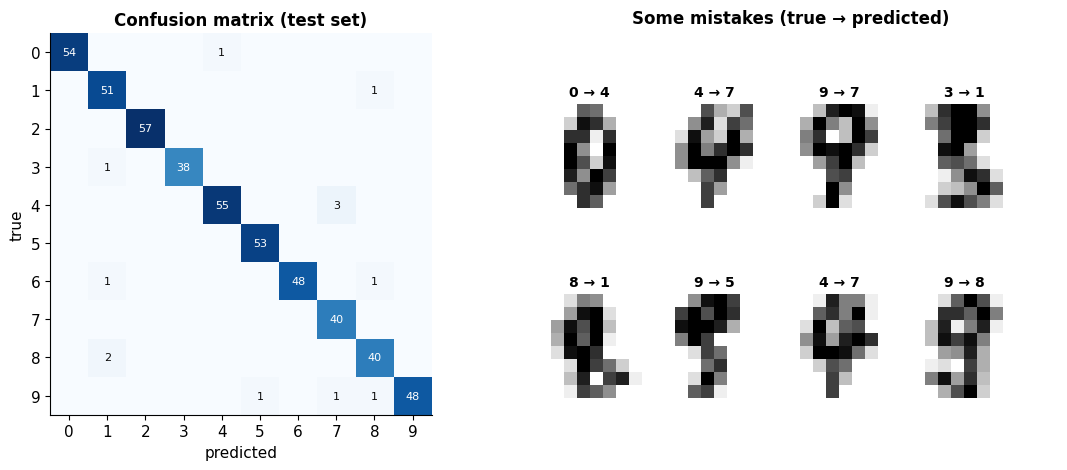

In [17]:
pred_te = softmax(Xg1[te_i] @ ThetaD).argmax(1)
CM = np.zeros((10, 10), int)
for t_, p_ in zip(yg[te_i], pred_te): CM[t_, p_] += 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax1.imshow(CM, cmap="Blues")
for i in range(10):
    for j in range(10):
        if CM[i, j]: ax1.text(j, i, CM[i, j], ha="center", va="center", fontsize=8, color="white" if CM[i, j] > 20 else C["ink"])
ax1.set(xticks=range(10), yticks=range(10), xlabel="predicted", ylabel="true", title="Confusion matrix (test set)"); ax1.grid(False)
wrong = np.where(pred_te != yg[te_i])[0][:8]
ax2.axis("off"); ax2.set_title("Some mistakes (true → predicted)")
for n_, w_ in enumerate(wrong):
    sub = fig.add_axes([0.50 + 0.06 * (n_ % 4) * 1.6, 0.48 - 0.38 * (n_ // 4), 0.08, 0.3])
    sub.imshow(Xg[te_i][w_].reshape(8, 8), cmap="gray_r"); sub.axis("off")
    sub.set_title(f"{yg[te_i][w_]} → {pred_te[w_]}", fontsize=10)
plt.show()

---
## 11. Reading the model: odds ratios and calibrated probabilities

### Odds ratios

Because the score is the log-odds, coefficients have a precise meaning: increasing feature $j$ by one unit (holding the rest fixed) **adds $\theta_j$ to the log-odds**, i.e. **multiplies the odds by $e^{\theta_j}$**. Here are the largest effects in the breast-cancer model (standardized features, so "one unit" = one standard deviation; label 1 = benign in this dataset):

In [18]:
names_bc = load_breast_cancer().feature_names
th_bc = h_newton[-1]
lr_bc = LogisticRegression(C=1.0, max_iter=5000).fit(Xbc, ybc)                  # moderately regularized, more stable coefficients
coef = pd.Series(lr_bc.coef_[0], index=names_bc)
top = coef.reindex(coef.abs().sort_values(ascending=False).index)[:8]
print(f"{'feature':<26} {'θ':>7} {'odds ratio e^θ':>15}")
for nm, v in top.items():
    print(f"{nm:<26} {v:7.2f} {np.exp(v):15.2f}")

feature                          θ  odds ratio e^θ
worst texture                -1.32            0.27
radius error                 -1.29            0.28
worst radius                 -1.03            0.36
area error                   -1.00            0.37
worst area                   -0.99            0.37
mean concave points          -0.96            0.38
worst concave points         -0.93            0.40
worst symmetry               -0.89            0.41


For example, the top row's odds ratio of 0.27 means one extra standard deviation of "worst texture" multiplies the odds of *benign* by 0.27, i.e. makes malignant much more likely. (Every top effect is below 1: larger, more irregular cells point toward malignancy.) Same caveats as notebook 05: these are associations, and correlated features (radius, perimeter and area are nearly the same measurement) split and trade weight, so individual coefficients should be read with care.

### Are the probabilities trustworthy?

A model is **calibrated** if, among all the cases where it says "70%," about 70% really are positive. Logistic regression is usually reasonably calibrated *when its assumptions roughly hold*, because maximum likelihood directly rewards honest probabilities. The danger is **overconfidence**, typically from too little regularization. Compare a sensibly regularized model with an unregularized one on held-out patients, looking at the probability each assigns to the *wrong* answer on its mistakes:

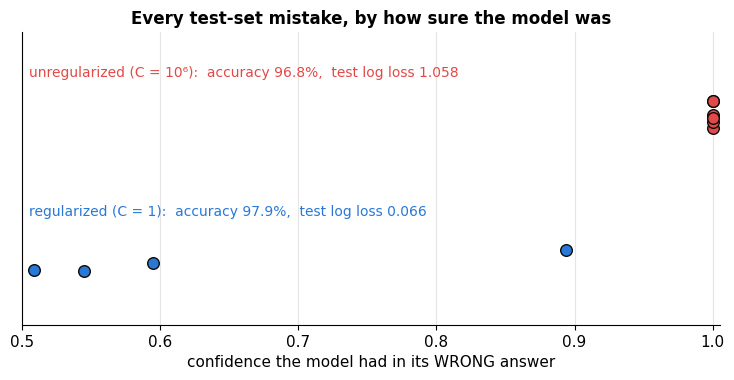

In [19]:
perm = np.random.default_rng(1).permutation(len(ybc)); tr_b, te_b = perm[:380], perm[380:]
models = {"regularized (C = 1)": LogisticRegression(C=1.0, max_iter=5000),
          "unregularized (C = 10⁶)": LogisticRegression(C=1e6, max_iter=50000)}
fig, ax = plt.subplots(figsize=(9, 3.8))
for row, ((name, mdl), col) in enumerate(zip(models.items(), [C["blue"], C["red"]])):
    pr = mdl.fit(Xbc[tr_b], ybc[tr_b]).predict_proba(Xbc[te_b])[:, 1]
    yt = ybc[te_b]; pred = (pr > 0.5).astype(int)
    conf_wrong = np.where(pred == 1, pr, 1 - pr)[pred != yt]          # confidence in the (wrong) predicted class
    ll = -np.mean(yt * np.log(np.clip(pr, 1e-15, 1)) + (1 - yt) * np.log(np.clip(1 - pr, 1e-15, 1)))
    ax.scatter(conf_wrong, np.full(len(conf_wrong), row) + np.random.default_rng(row).uniform(-0.12, 0.12, len(conf_wrong)),
               s=70, color=col, edgecolor=C["ink"], zorder=3)
    ax.text(0.505, row + 0.28, f"{name}:  accuracy {np.mean(pred == yt):.1%},  test log loss {ll:.3f}", fontsize=10, color=col)
ax.set(yticks=[], xlim=(0.5, 1.005), ylim=(-0.5, 1.6), xlabel="confidence the model had in its WRONG answer",
       title="Every test-set mistake, by how sure the model was")
plt.show()

Both models make a similar number of mistakes, so accuracy can't tell them apart. But the unregularized model makes its mistakes with near-total certainty, and the **log loss** (which charges $-\log(\text{probability of the truth})$, so a confident mistake costs a fortune) is many times worse. Good probabilities matter whenever a decision depends on *how* likely something is (medicine, finance, ranking), not just on which class wins. Notebook 10 covers turning probabilities into decisions with thresholds other than 0.5, and how to measure calibration properly with **reliability diagrams**.

---
## 12. Summary

| Step | Linear regression (05) | Logistic regression | Softmax regression |
|---|---|---|---|
| Model | $y \sim \mathcal{N}(\theta^\top x, \sigma^2)$ | $y \sim \text{Bernoulli}(\sigma(\theta^\top x))$ | $y \sim \text{Categorical}(\text{softmax}(\Theta^\top x))$ |
| Loss (MLE) | squared error | binary cross-entropy | categorical cross-entropy |
| Gradient | $\frac1m X^\top(X\theta - y)$ (×2) | $\frac1m X^\top(\sigma(X\theta) - y)$ | $\frac1m X^\top(P - Y)$ |
| Closed form? | yes | no (nonlinear equation) | no |
| Convex? | yes | yes ($X^\top S X \succeq 0$) | yes |
| MAP with Gaussian prior | ridge | $+\lambda\|\theta\|^2$; needed for separable data | same |

Key ideas: the **sigmoid** maps a linear score to a probability, and the score is the **log-odds**; the **decision boundary** $\theta^\top x = 0$ is linear; **cross-entropy** = negative log-likelihood, convex, with "prediction minus target" gradients; **separable data** needs regularization; **Newton/IRLS** converges in a few steps for small models; **feature maps** give curved boundaries; **softmax** handles many classes.

### ✏️ Exercises

1. Derive $\nabla_\theta J$ for the binary cross-entropy step by step, using $\sigma'(z) = \sigma(z)(1 - \sigma(z))$.
2. Show that softmax with $K = 2$ classes is exactly logistic regression with $\theta = \theta_1 - \theta_0$.
3. Show that adding the same vector $c$ to every $\theta_k$ doesn't change the softmax probabilities. What does that imply about the uniqueness of the MLE, and how does regularization fix it?
4. Implement **one-vs-rest**: train 10 separate binary logistic regressions on the digits ("is it a 3 or not?") and predict the class with the highest probability. Compare its accuracy with softmax regression.
5. Add $\ell_1$ regularization to logistic regression on the breast-cancer data using proximal gradient descent (notebook 07, exercise 3). Which features survive?
6. In the separable-data experiment, track the *direction* $w/\|w\|$ over training and compare it with the maximum-margin direction from an SVM (`sklearn.svm.SVC(kernel="linear", C=1e6)`).

### References

- CX 4240 Lecture 7 (Logistic Regression: Bernoulli likelihood, sigmoid, linear decision boundary, MLE and MAP, gradient descent) and Lecture 8 (multiclass logistic regression, softmax).
- ISYE 4600 W8 (Classification: logistic regression, gradient-based training) and HW3 (convexity of logistic regression).
- C. Bishop, *Pattern Recognition and Machine Learning*, Sections 4.3.2–4.3.4 (logistic regression, IRLS, softmax).
- K. Murphy, *Probabilistic Machine Learning: An Introduction* (2022), Chapter 10.
- D. Soudry et al., *The Implicit Bias of Gradient Descent on Separable Data*, JMLR (2018).
- C. Guo et al., *On Calibration of Modern Neural Networks*, ICML (2017).

**Next → [09 · Naive Bayes & Generative Classifiers](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/09_naive_bayes_generative.ipynb)**